# 以太坊 (ETH/USDT) 数据探索

数据来源：Binance，日频数据缓存于 `data/eth_usdt_1d.csv`。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import mplfinance as mpf
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

## 日频分析

In [2]:
df = pd.read_csv(PROJECT_ROOT / "data" / "eth_usdt_1d.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.set_index("timestamp").sort_index()
print(f"行数: {len(df)}, 日期范围: {df.index.min().date()} ~ {df.index.max().date()}")
df.head()

行数: 1826, 日期范围: 2021-01-01 ~ 2025-12-31


,open,high,low,close,volume
timestamp,,,,,
2021-01-01,737.61,749.11,715.62,728.52,3084.37850
2021-01-02,729.46,787.22,715.34,774.56,8325.47357
2021-01-03,774.60,1010.82,768.74,978.14,19330.21676
2021-01-04,978.03,1160.80,881.58,1042.10,26998.69336
2021-01-05,1043.81,1133.80,970.00,1100.22,18624.18143


(<Figure size 1600x1000 with 4 Axes>,
 [<Axes: ylabel='Price (USDT)'>, <Axes: >, <Axes: ylabel='Volume'>, <Axes: >])

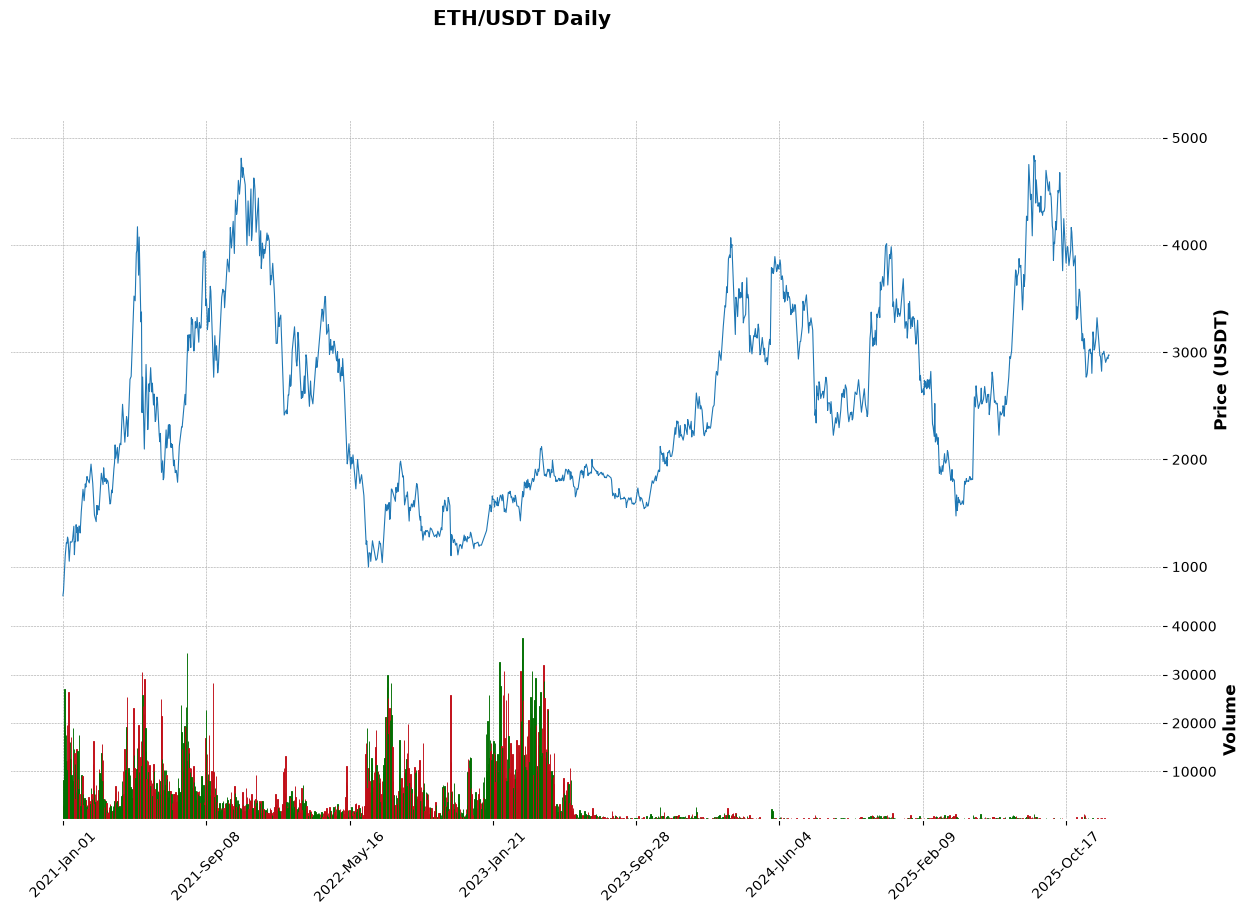

In [9]:
mpf.plot(
    df,
    type="line",
    volume=True,
    style="charles",
    title="ETH/USDT Daily",
    ylabel="Price (USDT)",
    ylabel_lower="Volume",
    figsize=(16, 10),
    returnfig=True
)

## 月频分析

In [3]:
monthly = df.resample("ME").agg(
    open=("open", "first"),
    high=("high", "max"),
    low=("low", "min"),
    close=("close", "last"),
    volume=("volume", "sum"),
)
monthly.columns = ["Open", "High", "Low", "Close", "Volume"]
print(f"月频数据行数: {len(monthly)}")
monthly.to_csv(PROJECT_ROOT / "data" / "eth_usdt_1m.csv")
monthly.head()

月频数据行数: 60


,Open,High,Low,Close,Volume
timestamp,,,,,
2021-01-31,737.61,1474.64,715.34,1313.57,402019.13012
2021-02-28,1312.35,2040.79,1270.00,1419.49,149015.18312
2021-03-31,1420.49,1949.41,1410.56,1916.27,159265.06706
2021-04-30,1920.93,2798.00,1521.60,2773.94,225315.79626
2021-05-31,2773.37,4375.04,1730.50,2704.95,452241.16973


findfont: Failed to find font weight medium, now using 400.


(<Figure size 1600x1000 with 4 Axes>,
 [<Axes: ylabel='Price (USDT)'>, <Axes: >, <Axes: ylabel='Volume'>, <Axes: >])

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


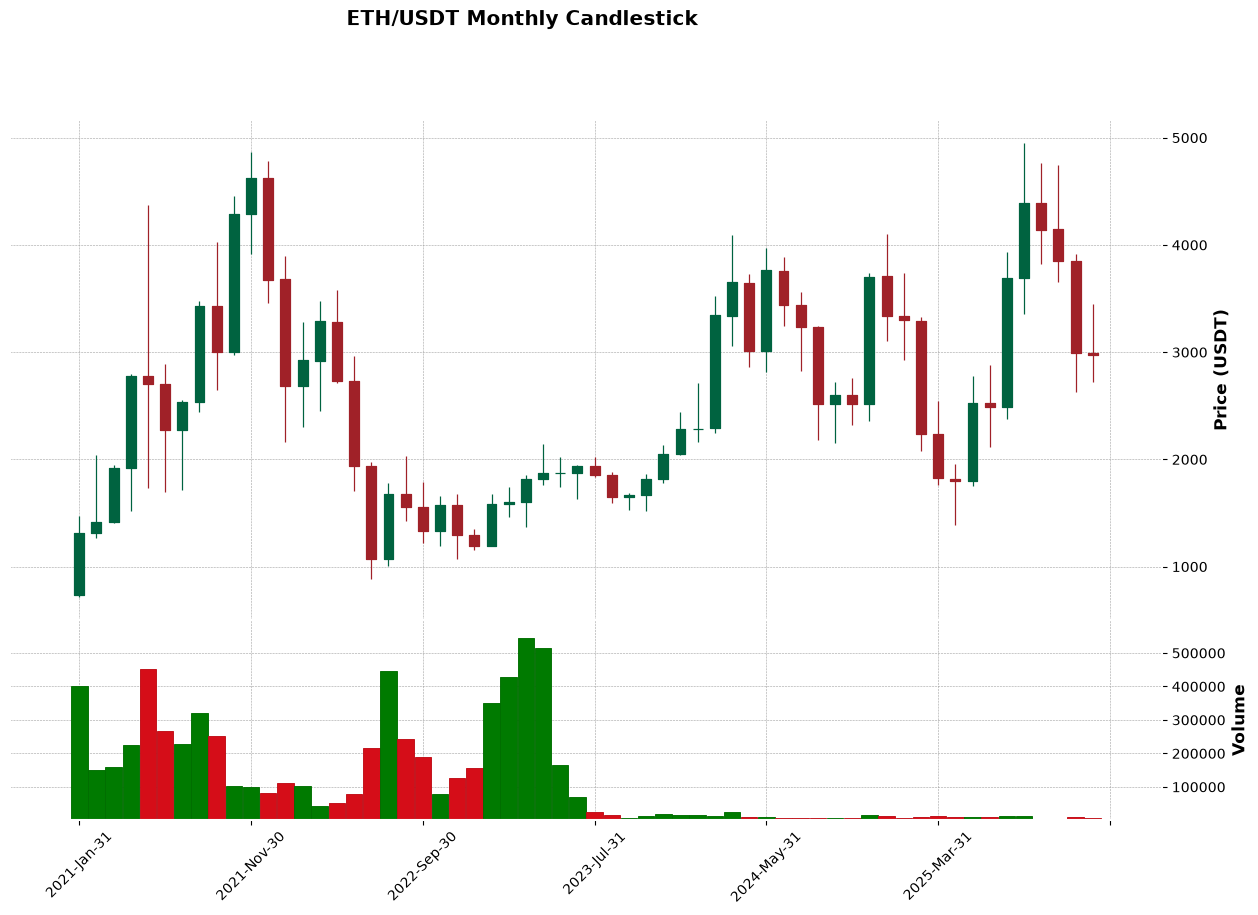

In [4]:
mpf.plot(
    monthly,
    type="candle",
    volume=True,
    style="charles",
    title="ETH/USDT Monthly Candlestick",
    ylabel="Price (USDT)",
    ylabel_lower="Volume",
    figsize=(16, 10),
    returnfig=True
)

## 月间价格极差分析

In [5]:
monthly["Range"] = monthly["High"] - monthly["Low"]

lag = pd.DataFrame(
    {
        "range_t": monthly["Range"].iloc[:-1].values,
        "range_t1": monthly["Range"].iloc[1:].values,
    },
    index=monthly.index[:-1],
)
print(f"点数: {len(lag)}, 覆盖 {lag.index.min().strftime('%Y-%m')} ~ {lag.index.max().strftime('%Y-%m')}")
lag.head()

点数: 59, 覆盖 2021-01 ~ 2025-11


,range_t,range_t1
timestamp,,
2021-01-31,759.30,770.79
2021-02-28,770.79,538.85
2021-03-31,538.85,1276.40
2021-04-30,1276.40,2644.54
2021-05-31,2644.54,1190.99


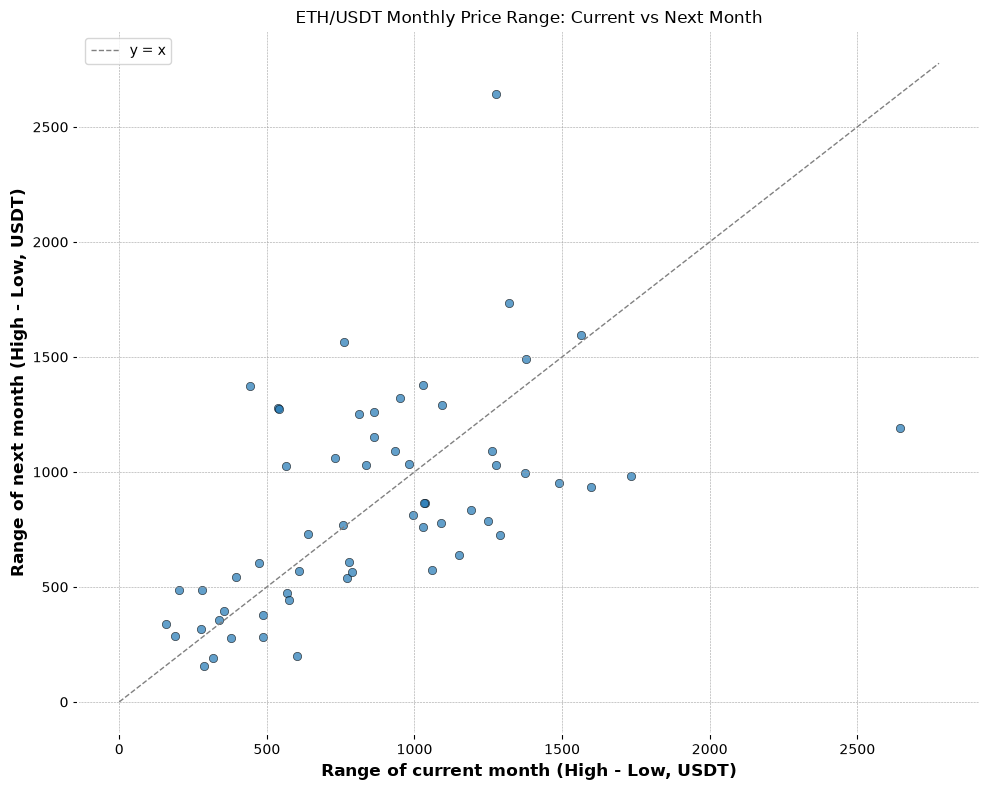

In [6]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(lag["range_t"], lag["range_t1"], alpha=0.7, edgecolors="k", linewidths=0.5)
limit = max(lag.max().max() * 1.05, 100)
ax.plot([0, limit], [0, limit], ls="--", color="gray", lw=1, label="y = x")
ax.set_xlabel("Range of current month (High - Low, USDT)")
ax.set_ylabel("Range of next month (High - Low, USDT)")
ax.set_title("ETH/USDT Monthly Price Range: Current vs Next Month")
ax.legend()
plt.tight_layout()
plt.show()